# trajopt-jax: a low-thrust rendezvous, the departure date solved for

A spacecraft with an electric engine leaves Earth on a date it chooses and meets Mars on a fixed arrival date, using as little propellant as it can. The planets are on circular, coplanar orbits, so the problem is small and solves in seconds; with a strong engine and no launch speed its answer tends to the Hohmann transfer, which is the check.

Source: [`examples/rendezvous.py`](https://github.com/thearn/trajopt-jax/blob/main/examples/rendezvous.py)

## The problem

Units: distance in AU, time in years (so the Sun's gravitational parameter is $\mu_\odot = 4\pi^2$), mass as a fraction of the starting mass. Time $t$ runs to $0$ at the arrival date.

**States** $\mathbf{s} = (x, y, v_x, v_y, m, t, c)$: position, velocity, mass, time and the cost $c$.

**Controls**: the throttle $\tau \in [0, 1]$ (a fraction of the engine's maximum thrust) and the thrust's direction, the angle $\alpha$ from the $x$ axis.

**Parameters** (the fields of `Case` in the source; every one can be set in the notebook)

| symbol | `Case` field | meaning | default |
|---|---|---|---|
| $R_1$, $R_2$ | `origin_au`, `target_au` | the departure and target orbits' radii | 1, 1.524 AU (Earth, Mars) |
| $\theta_2(0)$ | `arrive_phase_deg` | the target's angle on the arrival date | 180° |
| | `lead_deg` | the departure planet's angle on the arrival date, from where a Hohmann transfer needs it | 0° |
| $T_{\max}$ | `thrust_n` | the engine's thrust | 0.5 N |
| $I_{sp}$ | `isp_s` | its specific impulse | 3000 s |
| $m_0$ | `mass_kg` | the starting mass | 1500 kg |
| $v_{\infty,\max}$ | `vinf_kms` | the launch vehicle's hyperbolic excess speed | 3 km/s |
| $[T_{lo}, T_{hi}]$ | `window` | the flight time's bounds | 0.3–1.2 yr |
| $N$ | `segments` | stages | 60 |
| $w$ steps | `homotopy` | the cost's propellant weight, solved in turn | 0, 0.5, 1 |

**Planets**: on circular orbits, each a line of trigonometry, $\mathbf{r}_i(t) = R_i\,(\cos\theta_i(t), \sin\theta_i(t))$ with $\theta_i(t) = \theta_i(0) + n_i t$ and $n_i = \sqrt{\mu_\odot / R_i^3}$.

**Dynamics**: two-body motion about the Sun with the engine's acceleration,
$$
\dot x = v_x, \quad \dot y = v_y, \qquad
\begin{pmatrix} \dot v_x \\ \dot v_y \end{pmatrix} = -\frac{\mu_\odot}{r^3} \begin{pmatrix} x \\ y \end{pmatrix} + \frac{a_{\max}\, \tau}{m} \begin{pmatrix} \cos\alpha \\ \sin\alpha \end{pmatrix}, \qquad
\dot m = -\dot m_{\max}\, \tau, \qquad \dot t = 1,
$$
with $a_{\max} = T_{\max} / m_0$ and $\dot m_{\max} = T_{\max} / (I_{sp}\, g_0\, m_0)$.

**Objective**: the least propellant, $m_0\,(1 - m(0))$. The cost's rate blends it with an energy-like term,
$$
\dot c = \dot m_{\max} \left( w\, \tau + (1 - w)\, \tau^2 \right), \qquad \min J = c(0),
$$
solved for the weights $w$ in `homotopy`, each solve seeded by the last. At $w = 1$ the optimum is bang-bang (full thrust or none); the smooth $w = 0$ problem finds the transfer's shape first. The weight reaches the dynamics as per-stage model data, so one compiled solver serves every step.

**Path constraint**: $m \ge 0.2$ (an iterate of a strong engine must not burn the mass away).

**Departure** (a free start, held by constraints): on a date $t_0$ inside the window, at the inner planet, leaving at most at the launch vehicle's speed, with all the starting mass,
$$
\mathbf{r}(t_0) = \mathbf{r}_1(t_0), \qquad \lVert \mathbf{v}(t_0) - \mathbf{v}_1(t_0) \rVert \le v_{\infty,\max}, \qquad -T_{hi} \le t_0 \le -T_{lo}, \qquad m(t_0) = 1 .
$$

**Arrival** (a rendezvous on the fixed date):
$$
t_f = 0, \qquad \mathbf{r}(0) = \mathbf{r}_2(0), \qquad \mathbf{v}(0) = \mathbf{v}_2(0) .
$$

## How trajopt-jax transcribes it

One leg of $N$ stages. Each stage's state is a cubic collocated at the Radau IIA points; the controls are linear between knots. The departure is a *start event* (`Stages.start_free` names the states left free at the first stage, `start_events` the constraints that hold them), the arrival an end event on the leg; the flight time is the leg's free duration. A primal-dual interior-point method solves the result, its linear algebra a Riccati recursion over the stages.

In [1]:
try:  # on Colab: install trajopt-jax
    import google.colab  # noqa: F401
    %pip install -q git+https://github.com/thearn/trajopt-jax matplotlib
    !wget -q https://raw.githubusercontent.com/thearn/trajopt-jax/main/examples/rendezvous.py
except ImportError:
    import sys
    sys.path.insert(0, 'examples' if __import__('os').path.isdir('examples') else '.')

import jax
jax.config.update('jax_enable_x64', True)
import rendezvous as rz

## Earth to Mars with a small engine

The default `Case`: 0.5 N on 1500 kg, launched at up to 3 km/s.

In [2]:
case = rz.Case()
out = rz.solve(case)
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in out.items() if k not in ('X', 'U', 'prob', 'origin', 'target')}

{'status': 'converged',
 'converged': True,
 'steps': [(0.0, 'converged', 45, 3.4),
  (0.5, 'converged', 138, 5.0),
  (1.0, 'converged', 60, 5.7)],
 'seconds': 5.7,
 'flight_yr': 0.757,
 'lead_deg': 52.449,
 'burn_centre_to_arrival_yr': 0.726,
 'lead_at_burn_centre_deg': 47.217,
 'propellant_kg': 184.904,
 'dv_kms': 3.87,
 'vinf_kms': 3.0}

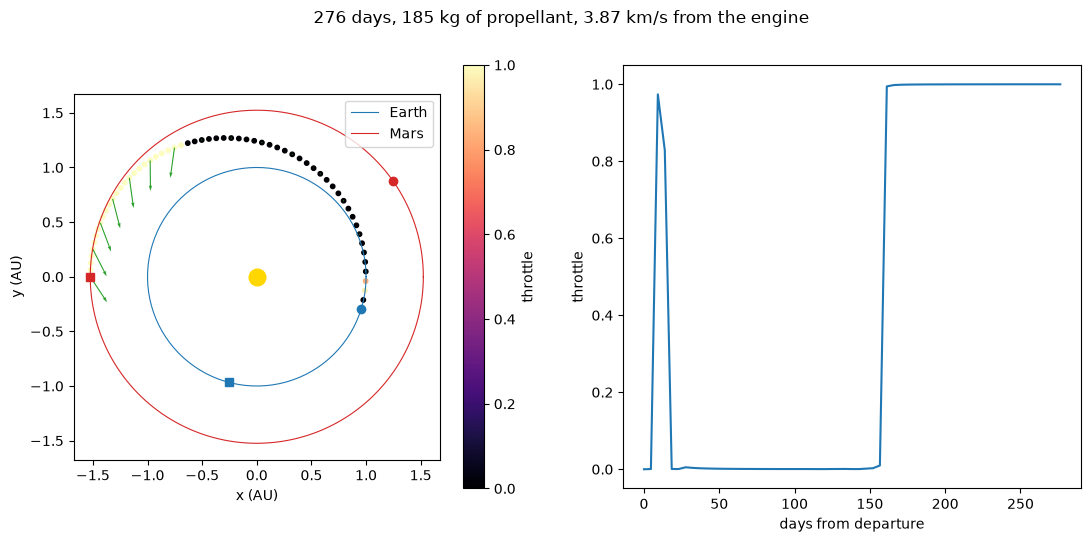

In [3]:
import matplotlib.pyplot as plt
import numpy as np


def plot(out, title):
    prob, s = out['prob'], out['X'][:, :out['prob'].ns] * out['prob'].ref
    throttle, alpha = out['X'][:, prob.ns], out['X'][:, prob.ns + 1]
    days = (s[:, 5] - s[0, 5]) * 365.25
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 5.5))
    th = np.linspace(0, 2 * np.pi, 200)
    for orbit, colour, name in ((out['origin'], 'tab:blue', 'Earth'), (out['target'], 'tab:red', 'Mars')):
        a0.plot(orbit.radius * np.cos(th), orbit.radius * np.sin(th), color=colour, lw=0.8, label=name)
        for t, marker in ((s[0, 5], 'o'), (0.0, 's')):
            p = np.asarray(orbit.state(t))
            a0.plot(p[0], p[1], marker, color=colour)
    sc = a0.scatter(s[:, 0], s[:, 1], c=throttle, cmap='magma', vmin=0, vmax=1, s=10)
    k = slice(None, None, 4)
    a0.quiver(s[k, 0], s[k, 1], throttle[k] * np.cos(alpha[k]), throttle[k] * np.sin(alpha[k]), color='tab:green', scale=12, width=0.003)
    a0.plot(0, 0, 'o', color='gold', ms=12)
    a0.set_aspect('equal'); a0.set_xlabel('x (AU)'); a0.set_ylabel('y (AU)'); a0.legend(loc='upper right')
    fig.colorbar(sc, ax=a0, label='throttle')
    a1.plot(days, throttle)
    a1.set_xlabel('days from departure'); a1.set_ylabel('throttle'); a1.set_ylim(-0.05, 1.05)
    fig.suptitle(title)


plot(out, f"{out['flight_yr'] * 365.25:.0f} days, {out['propellant_kg']:.0f} kg of propellant, {out['dv_kms']:.2f} km/s from the engine")

Circles: the planets on the departure date; squares: on the arrival date. Green arrows: the thrust's direction, scaled by throttle. The engine fires near the start and the end (the minimum-propellant pattern) and coasts between.

## The check: the Hohmann transfer

With a strong engine (5 N, burns of about ten days against a nine-month flight) and no launch speed, the optimum should approach the impulsive Hohmann transfer. For circular orbits of radii $R_1$ (departure) and $R_2$ (target) its two burns and flight time are
$$
\Delta v_1 = \sqrt{\frac{\mu_\odot}{R_1}} \left| \sqrt{\frac{2 R_2}{R_1 + R_2}} - 1 \right|, \qquad
\Delta v_2 = \sqrt{\frac{\mu_\odot}{R_2}} \left| 1 - \sqrt{\frac{2 R_1}{R_1 + R_2}} \right|, \qquad
t_H = \pi \sqrt{\frac{(R_1 + R_2)^3}{8 \mu_\odot}},
$$
and at departure the target must lead the inner planet by $\phi = \pi - n_2\, t_H$ (44.4° for Earth and Mars).

Two details make the comparison fair. A finite burn straddles the impulse it stands for, so the solver's *burn centre* (its throttle-weighted mean time) is compared with the Hohmann departure, not the burn's start. And with no launch speed, departing earlier and coasting beside Earth until the burn costs nothing, so the departure date itself is not unique: the window is kept close to $t_H$.

                                   trajopt-jax     Hohmann
speed change (km/s)                      5.605       5.596
burn centre to arrival (days)          260.192     258.910
lead at the burn centre (deg)           44.953      44.361
solve: converged, 9.6 s


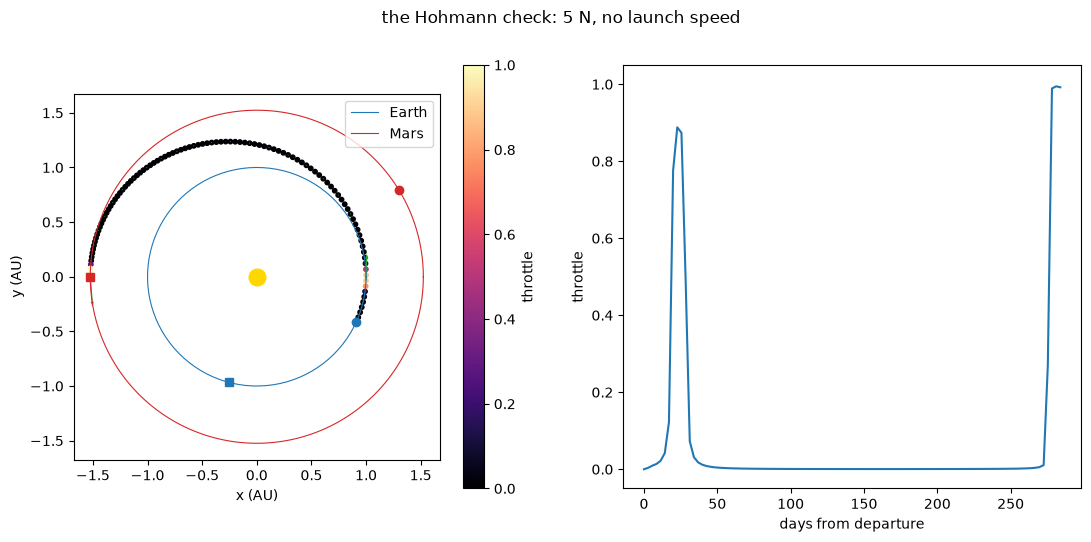

In [4]:
h = rz.hohmann(rz.HOHMANN_CASE)
chk = rz.solve(rz.HOHMANN_CASE)
rows = [('speed change (km/s)', chk['dv_kms'], h['dv_kms']),
        ('burn centre to arrival (days)', chk['burn_centre_to_arrival_yr'] * 365.25, h['flight_yr'] * 365.25),
        ('lead at the burn centre (deg)', chk['lead_at_burn_centre_deg'], h['lead_deg'])]
print(f"{'':32s}{'trajopt-jax':>14s}{'Hohmann':>12s}")
for name, a, b in rows:
    print(f'{name:32s}{a:14.3f}{b:12.3f}')
print(f"solve: {chk['status']}, {chk['seconds']} s")
plot(chk, 'the Hohmann check: 5 N, no launch speed')

## Try your own

Every field of `Case` can be changed: other orbits (Earth to Venus is `target_au=0.723`, an inward transfer), another engine, a bigger launch vehicle, another arrival phase. Moving `lead_deg` away from 0 shifts the planets off the Hohmann alignment, and the solver finds a different departure date. With a small engine and a 3 km/s launch the impulsive alignment is not the low-thrust optimum, so a shifted phase can even cost less propellant.

An inward transfer to Venus needs more of the engine: about 5.2 km/s even impulsively, more than 0.5 N on 1500 kg delivers in a Venus-length flight, so the Venus case uses 1 N and a shorter window.

In [5]:
from dataclasses import replace

for lead in (0.0, 20.0, 40.0):
    o = rz.solve(replace(rz.Case(), lead_deg=lead))
    print(f"lead {lead:5.1f} deg: {o['status']:10s} departs {o['flight_yr'] * 365.25:5.0f} days before arrival, "
          f"{o['propellant_kg']:6.1f} kg, launch {o['vinf_kms']:.2f} km/s")

venus = rz.solve(replace(rz.Case(), target_au=0.723, thrust_n=1.0, window=(0.25, 0.9)))
print(f"Venus: {venus['status']}, {venus['flight_yr'] * 365.25:.0f} days, {venus['propellant_kg']:.1f} kg")

lead   0.0 deg: converged  departs   276 days before arrival,  184.9 kg, launch 3.00 km/s


lead  20.0 deg: converged  departs   305 days before arrival,  132.3 kg, launch 2.90 km/s


lead  40.0 deg: converged  departs   348 days before arrival,  132.0 kg, launch 2.90 km/s


Venus: converged, 246 days, 204.7 kg
